# DataCo Supply Chain - Dự đoán giao hàng trễ (Submission 1)

**Bài toán:** Binary classification - dự đoán đơn hàng có bị giao trễ hay không (`Late_delivery_risk`: 1 = trễ, 0 = không trễ).

**Nội dung notebook:**
1. Đọc dữ liệu
2. Tìm hiểu tổng quan dữ liệu (kích thước, kiểu dữ liệu, missing, trùng lặp)
3. Chọn biến mục tiêu (target)
4. Kiểm tra rò rỉ dữ liệu (data leakage)
5. EDA - Vận chuyển
6. EDA - Địa lý
7. EDA - Sản phẩm và khách hàng
8. EDA - Biến số và tương quan
9. Tiền xử lý dữ liệu (chọn cột, encoding)
10. Tổng kết

*Ghi chú: phần EDA theo thời gian (order date) tạm thời chưa đưa vào, sẽ nghiên cứu và bổ sung sau.*

## 0. Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# tạo thư mục để lưu hình
if not os.path.exists('figures'):
    os.makedirs('figures')
if not os.path.exists('results'):
    os.makedirs('results')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 100)
print('Import xong!')

Import xong!


## 1. Đọc dữ liệu

In [2]:
# file csv bị lỗi font nếu đọc utf-8 nên mình dùng encoding latin-1
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin-1')
print('Đọc dữ liệu thành công')

Đọc dữ liệu thành công


In [3]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
# đọc thêm file mô tả các cột
desc = pd.read_csv('DescriptionDataCoSupplyChain.csv')
desc

,FIELDS,DESCRIPTION
0,Type,: Type of transaction made
1,Days for shipping (real),: Actual shipping days of the purchased product
2,Days for shipment (scheduled),: Days of scheduled delivery of the purchased...
3,Benefit per order,: Earnings per order placed
4,Sales per customer,: Total sales per customer made per customer
5,Delivery Status,: Delivery status of orders: Advance shipping...
6,Late_delivery_risk,: Categorical variable that indicates if send...
7,Category Id,: Product category code
8,Category Name,: Description of the product category
9,Customer City,: City where the customer made the purchase


## 2. Tổng quan dữ liệu

In [5]:
print('Số dòng:', df.shape[0])
print('Số cột:', df.shape[1])

Số dòng: 180519
Số cột: 53


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [7]:
# đếm số cột theo kiểu dữ liệu
print(df.dtypes.value_counts())

object     24
float64    15
int64      14
Name: count, dtype: int64


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


In [9]:
# khoảng thời gian của dữ liệu
ngay_dat = pd.to_datetime(df['order date (DateOrders)'], format='%m/%d/%Y %H:%M')
print('Ngày đặt hàng sớm nhất:', ngay_dat.min())
print('Ngày đặt hàng muộn nhất:', ngay_dat.max())

Ngày đặt hàng sớm nhất:

 2015-01-01 00:00:00
Ngày đặt hàng muộn nhất: 2018-01-31 23:38:00


### 2.1 Kiểm tra giá trị thiếu (missing)

In [10]:
missing = df.isnull().sum()
missing_percent = df.isnull().sum() / len(df) * 100
missing_df = pd.DataFrame({'so_luong_missing': missing, 'phan_tram': missing_percent})
missing_df = missing_df[missing_df['so_luong_missing'] > 0]
missing_df = missing_df.sort_values('phan_tram', ascending=False)
print(missing_df)

                     so_luong_missing   phan_tram
Product Description            180519  100.000000
Order Zipcode                  155679   86.239676
Customer Lname                      8    0.004432
Customer Zipcode                    3    0.001662


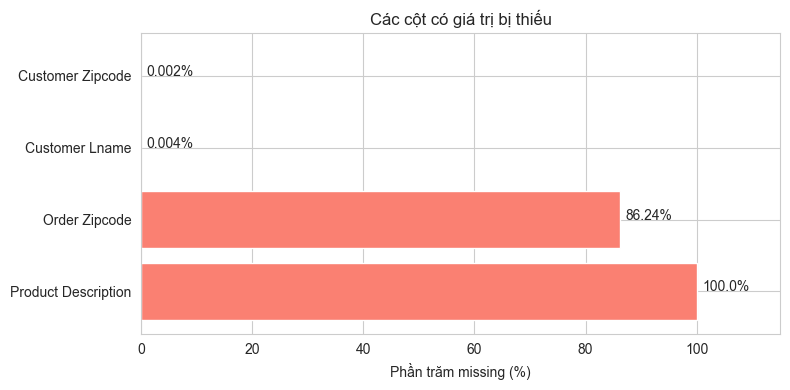

In [11]:
plt.figure(figsize=(8, 4))
plt.barh(missing_df.index, missing_df['phan_tram'], color='salmon')
plt.xlabel('Phần trăm missing (%)')
plt.title('Các cột có giá trị bị thiếu')
for i in range(len(missing_df)):
    plt.text(missing_df['phan_tram'].iloc[i] + 1, i, str(round(missing_df['phan_tram'].iloc[i], 3)) + '%')
plt.xlim(0, 115)
plt.tight_layout()
plt.savefig('figures/fig01_missing.png')
plt.show()

**Nhận xét:** `Product Description` bị thiếu 100% và `Order Zipcode` thiếu khoảng 86% nên sẽ bỏ 2 cột này. `Customer Lname` (8 dòng) và `Customer Zipcode` (3 dòng) thiếu rất ít và mình cũng không dùng 2 cột này để train.

### 2.2 Kiểm tra dòng trùng lặp và số giá trị khác nhau

In [12]:
print('Số dòng trùng lặp:', df.duplicated().sum())
print('Số Order Item Id khác nhau:', df['Order Item Id'].nunique())
print('Số Order Id khác nhau:', df['Order Id'].nunique())

Số dòng trùng lặp: 0
Số Order Item Id khác nhau: 180519
Số Order Id khác nhau: 65752


Mỗi dòng là một **item trong đơn hàng** (Order Item Id là duy nhất), một đơn (Order Id) có thể có nhiều dòng.

In [13]:
# số giá trị khác nhau của từng cột
nunique = df.nunique().sort_values()
print(nunique)

Product Description                   0
Product Status                        1
Customer Password                     1
Customer Email                        1
Late_delivery_risk                    2
Customer Country                      2
Customer Segment                      3
Type                                  4
Shipping Mode                         4
Delivery Status                       4
Days for shipment (scheduled)         4
Order Item Quantity                   5
Market                                5
Days for shipping (real)              7
Order Status                          9
Department Id                        11
Department Name                      11
Order Item Discount Rate             18
Order Region                         23
Customer State                       46
Category Name                        50
Category Id                          51
Product Category Id                  51
Product Price                        75
Order Item Product Price             75


In [14]:
# những cột chỉ có 1 giá trị thì không có ích cho mô hình
for col in df.columns:
    if df[col].nunique() <= 1:
        print(col, '-> chỉ có', df[col].nunique(), 'giá trị:', df[col].unique()[:3])

Customer Email -> chỉ có 1 giá trị: ['XXXXXXXXX']
Customer Password -> chỉ có 1 giá trị: ['XXXXXXXXX']
Product Description -> chỉ có 0 giá trị: [nan]


Product Status -> chỉ có 1 giá trị: [0]


In [15]:
# các cột thông tin cá nhân bị che
print(df['Customer Email'].unique()[:5])
print(df['Customer Password'].unique()[:5])

['XXXXXXXXX']
['XXXXXXXXX']


## 3. Chọn biến mục tiêu (target)

In [16]:
print(df['Late_delivery_risk'].value_counts())
print()
print(df['Late_delivery_risk'].value_counts(normalize=True) * 100)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


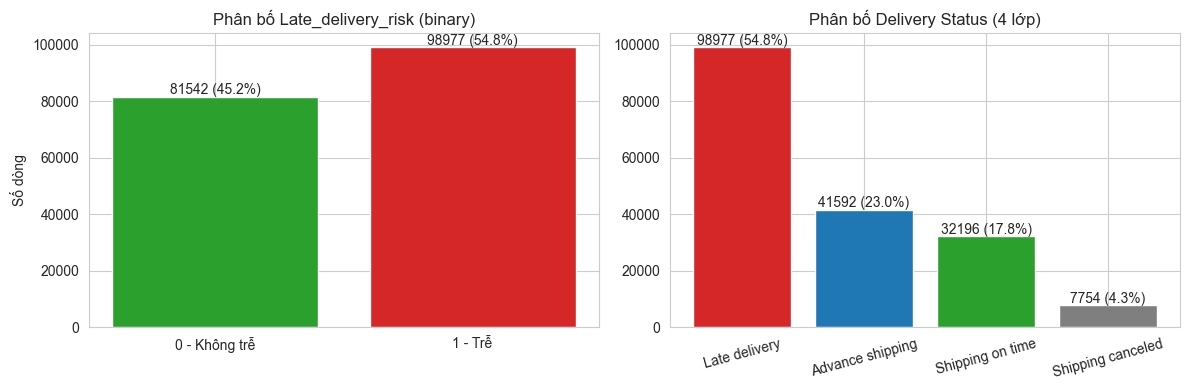

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

counts = df['Late_delivery_risk'].value_counts().sort_index()
ax[0].bar(['0 - Không trễ', '1 - Trễ'], counts.values, color=['tab:green', 'tab:red'])
for i in range(len(counts)):
    ax[0].text(i, counts.values[i] + 1000, str(counts.values[i]) + ' (' + str(round(counts.values[i] / len(df) * 100, 1)) + '%)', ha='center')
ax[0].set_title('Phân bố Late_delivery_risk (binary)')
ax[0].set_ylabel('Số dòng')

counts2 = df['Delivery Status'].value_counts()
ax[1].bar(counts2.index, counts2.values, color=['tab:red', 'tab:blue', 'tab:green', 'tab:gray'])
for i in range(len(counts2)):
    ax[1].text(i, counts2.values[i] + 1000, str(counts2.values[i]) + ' (' + str(round(counts2.values[i] / len(df) * 100, 1)) + '%)', ha='center')
ax[1].set_title('Phân bố Delivery Status (4 lớp)')
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('figures/fig02_target.png')
plt.show()

In [18]:
# xem thử Order Status
print(df['Order Status'].value_counts())
print()
print(df['Order Status'].value_counts(normalize=True) * 100)

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

Order Status
COMPLETE           32.955534
PENDING_PAYMENT    22.065267
PROCESSING         12.132795
PENDING            11.204915
CLOSED             10.866446
ON_HOLD             5.431007
SUSPECTED_FRAUD     2.250179
CANCELED            2.045214
PAYMENT_REVIEW      1.048643
Name: proportion, dtype: float64


**Nhận xét:**
- `Late_delivery_risk` có tỉ lệ 54.8% / 45.2% -> khá cân bằng, phù hợp làm **binary classification**.
- `Delivery Status` có 4 lớp, lớp `Shipping canceled` chỉ 4.3% -> có thể làm multiclass sau.
- `Order Status` có 9 lớp, mất cân bằng nhiều và là trạng thái xử lý đơn (không phải giao hàng) -> không chọn làm target.

=> **Chọn target là `Late_delivery_risk`.**

## 4. Kiểm tra rò rỉ dữ liệu (data leakage)

Rò rỉ dữ liệu là khi feature chứa thông tin chỉ biết **sau khi** đã giao hàng. Nếu dùng thì mô hình sẽ "gian lận" và có độ chính xác ảo.

In [19]:
# so sánh Delivery Status với target
ct = pd.crosstab(df['Delivery Status'], df['Late_delivery_risk'])
print(ct)

Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0


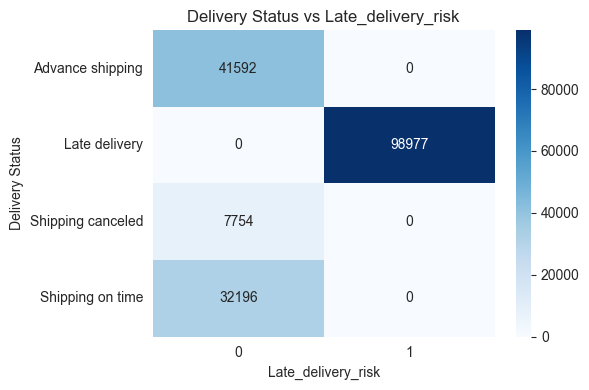

In [20]:
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Delivery Status vs Late_delivery_risk')
plt.tight_layout()
plt.savefig('figures/fig03_leak_delivery_status.png')
plt.show()

In [21]:
# nếu số ngày giao thực tế > số ngày dự kiến thì có phải là trễ không?
df['tre_theo_luat'] = (df['Days for shipping (real)'] > df['Days for shipment (scheduled)']).astype(int)
dung = (df['tre_theo_luat'] == df['Late_delivery_risk']).sum()
print('Số dòng khớp:', dung, '/', len(df))
print('Tỉ lệ khớp:', round(dung / len(df) * 100, 2), '%')

Số dòng khớp: 176096 / 180519
Tỉ lệ khớp: 97.55 %


In [22]:
# xem những dòng không khớp là gì
khong_khop = df[df['tre_theo_luat'] != df['Late_delivery_risk']]
print(khong_khop['Delivery Status'].value_counts())

Delivery Status
Shipping canceled    4423
Name: count, dtype: int64


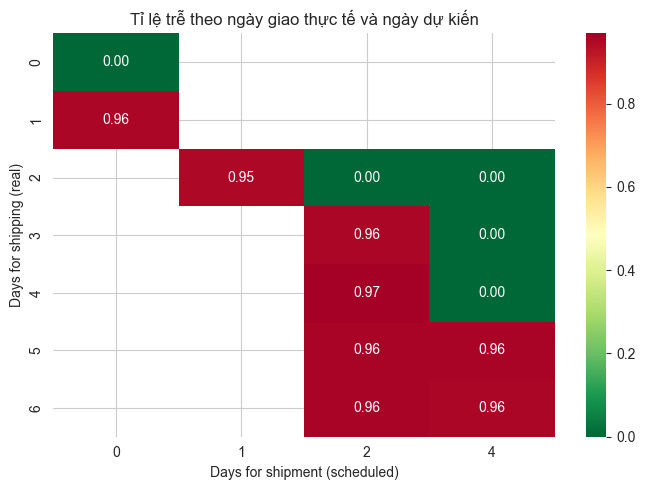

In [23]:
# vẽ heatmap tỉ lệ trễ theo số ngày thực tế và số ngày dự kiến
pivot = df.pivot_table(index='Days for shipping (real)', columns='Days for shipment (scheduled)', values='Late_delivery_risk', aggfunc='mean')
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn_r')
plt.title('Tỉ lệ trễ theo ngày giao thực tế và ngày dự kiến')
plt.tight_layout()
plt.savefig('figures/fig04_leak_real_vs_scheduled.png')
plt.show()

In [24]:
# Order Status: các đơn bị hủy / nghi gian lận thì Delivery Status là gì?
ct2 = pd.crosstab(df['Order Status'], df['Delivery Status'])
print(ct2)

Delivery Status  Advance shipping  Late delivery  Shipping canceled  \
Order Status                                                          
CANCELED                        0              0               3692   
CLOSED                       4809          11109                  0   
COMPLETE                    14136          34199                  0   
ON_HOLD                      2413           5450                  0   
PAYMENT_REVIEW                420           1082                  0   
PENDING                      4857          11712                  0   
PENDING_PAYMENT              9588          22922                  0   
PROCESSING                   5369          12503                  0   
SUSPECTED_FRAUD                 0              0               4062   

Delivery Status  Shipping on time  
Order Status                       
CANCELED                        0  
CLOSED                       3698  
COMPLETE                    11156  
ON_HOLD                      1941  
PA

**Nhận xét:**
- `Delivery Status = Late delivery` <=> `Late_delivery_risk = 1` (trùng 100%).
- Chỉ cần luật `real > scheduled` đã đúng ~97.5% (những dòng không khớp đều là đơn bị hủy).
- `Order Status` CANCELED/SUSPECTED_FRAUD <=> `Shipping canceled`, cũng là thông tin sau khi xử lý đơn.

=> Phải **bỏ** các cột: `Delivery Status`, `Days for shipping (real)`, `shipping date (DateOrders)`, `Order Status`.

In [25]:
df = df.drop(columns=['tre_theo_luat'])

## 5. EDA - Vận chuyển

In [26]:
# tỉ lệ trễ trung bình của toàn bộ dữ liệu
ti_le_tb = df['Late_delivery_risk'].mean() * 100
print('Tỉ lệ trễ trung bình:', round(ti_le_tb, 2), '%')

Tỉ lệ trễ trung bình: 54.83 %


In [27]:
# tỉ lệ trễ theo Shipping Mode
ship = df.groupby('Shipping Mode')['Late_delivery_risk'].agg(['mean', 'count'])
ship['mean'] = ship['mean'] * 100
ship = ship.sort_values('mean', ascending=False)
print(ship)

                     mean   count
Shipping Mode                    
First Class     95.322499   27814
Second Class    76.632781   35216
Same Day        45.743042    9737
Standard Class  38.071683  107752


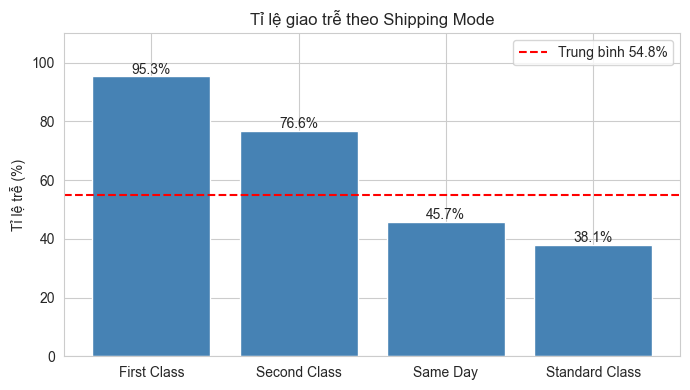

In [28]:
plt.figure(figsize=(7, 4))
plt.bar(ship.index, ship['mean'], color='steelblue')
plt.axhline(ti_le_tb, color='red', linestyle='--', label='Trung bình ' + str(round(ti_le_tb, 1)) + '%')
for i in range(len(ship)):
    plt.text(i, ship['mean'].iloc[i] + 1, str(round(ship['mean'].iloc[i], 1)) + '%', ha='center')
plt.ylabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo Shipping Mode')
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.savefig('figures/fig05_late_by_shipping_mode.png')
plt.show()

In [29]:
# tỉ lệ trễ theo số ngày giao dự kiến
sched = df.groupby('Days for shipment (scheduled)')['Late_delivery_risk'].agg(['mean', 'count'])
sched['mean'] = sched['mean'] * 100
print(sched)

                                    mean   count
Days for shipment (scheduled)                   
0                              45.743042    9737
1                              95.322499   27814
2                              76.632781   35216
4                              38.071683  107752


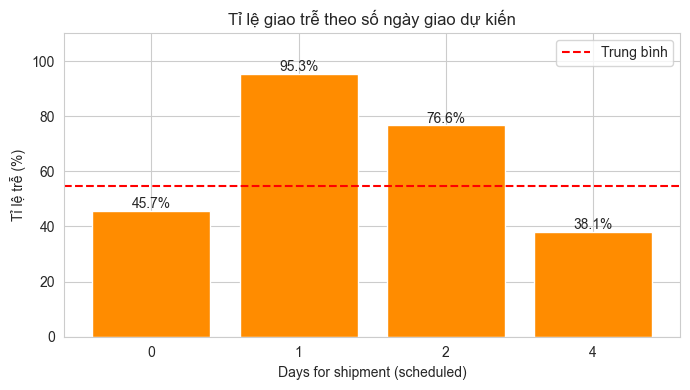

In [30]:
plt.figure(figsize=(7, 4))
plt.bar(sched.index.astype(str), sched['mean'], color='darkorange')
plt.axhline(ti_le_tb, color='red', linestyle='--', label='Trung bình')
for i in range(len(sched)):
    plt.text(i, sched['mean'].iloc[i] + 1, str(round(sched['mean'].iloc[i], 1)) + '%', ha='center')
plt.xlabel('Days for shipment (scheduled)')
plt.ylabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo số ngày giao dự kiến')
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.savefig('figures/fig06_late_by_scheduled_days.png')
plt.show()

Days for shipment (scheduled)     0      1      2       4
Shipping Mode                                            
First Class                       0  27814      0       0
Same Day                       9737      0      0       0
Second Class                      0      0  35216       0
Standard Class                    0      0      0  107752


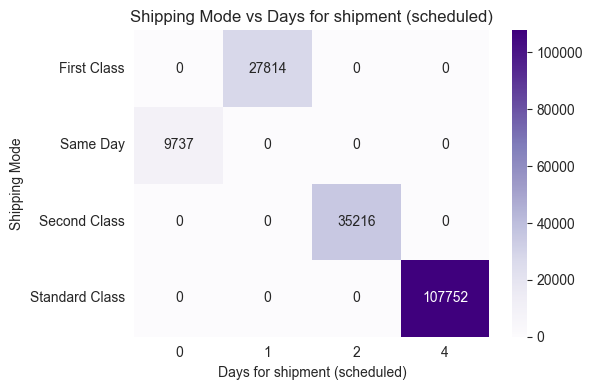

In [31]:
# Shipping Mode và số ngày dự kiến có liên quan với nhau không?
ct3 = pd.crosstab(df['Shipping Mode'], df['Days for shipment (scheduled)'])
print(ct3)
plt.figure(figsize=(6, 4))
sns.heatmap(ct3, annot=True, fmt='d', cmap='Purples')
plt.title('Shipping Mode vs Days for shipment (scheduled)')
plt.tight_layout()
plt.savefig('figures/fig07_shipping_mode_vs_scheduled.png')
plt.show()

**Nhận xét:**
- `First Class` trễ ~95%, `Second Class` ~77%, `Same Day` ~46%, `Standard Class` ~38%.
- Mỗi Shipping Mode gắn với đúng 1 giá trị số ngày dự kiến -> 2 cột này gần như là một (trùng thông tin).
- Đây sẽ là feature quan trọng nhất.

## 6. EDA - Địa lý

In [32]:
market = df.groupby('Market')['Late_delivery_risk'].agg(['mean', 'count'])
market['mean'] = market['mean'] * 100
market = market.sort_values('mean', ascending=False)
print(market)

                   mean  count
Market                        
Europe        55.207753  50252
Pacific Asia  55.046049  41260
USCA          54.800574  25799
Africa        54.589289  11614
LATAM         54.355158  51594


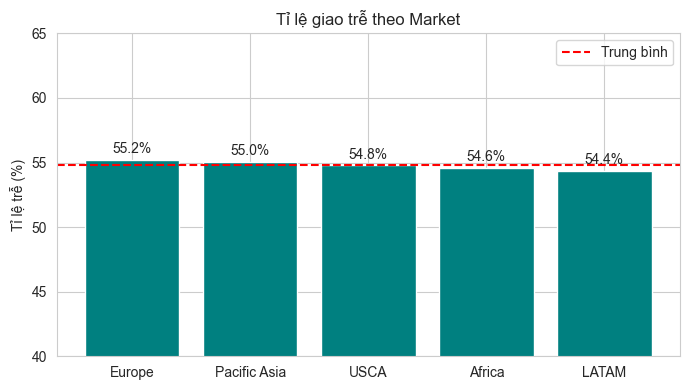

In [33]:
plt.figure(figsize=(7, 4))
plt.bar(market.index, market['mean'], color='teal')
plt.axhline(ti_le_tb, color='red', linestyle='--', label='Trung bình')
for i in range(len(market)):
    plt.text(i, market['mean'].iloc[i] + 0.5, str(round(market['mean'].iloc[i], 1)) + '%', ha='center')
plt.ylabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo Market')
plt.ylim(40, 65)
plt.legend()
plt.tight_layout()
plt.savefig('figures/fig08_late_by_market.png')
plt.show()

In [34]:
region = df.groupby('Order Region')['Late_delivery_risk'].agg(['mean', 'count'])
region['mean'] = region['mean'] * 100
region = region.sort_values('mean')
print(region)

                      mean  count
Order Region                     
Canada           48.800834    959
West Africa      52.840909   3696
Caribbean        53.077663   8318
Southern Africa  53.327571   1157
West of USA      53.959715   7993
Oceania          54.020497  10148
Northern Europe  54.044118   9792
South America    54.308671  14935
Eastern Asia     54.326923   7280
Southern Europe  54.384477   9431
North Africa     54.517327   3232
Central America  54.754596  28341
US Center        55.240360   5887
West Asia        55.283741   6009
Central Asia     55.334539    553
Southeast Asia   55.529930   9539
East of USA      55.661605   6915
Eastern Europe   55.663265   3920
South of  USA    55.772559   4045
Western Europe   55.848611  27109
East Africa      55.939525   1852
South Asia       56.266977   7731
Central Africa   57.960644   1677


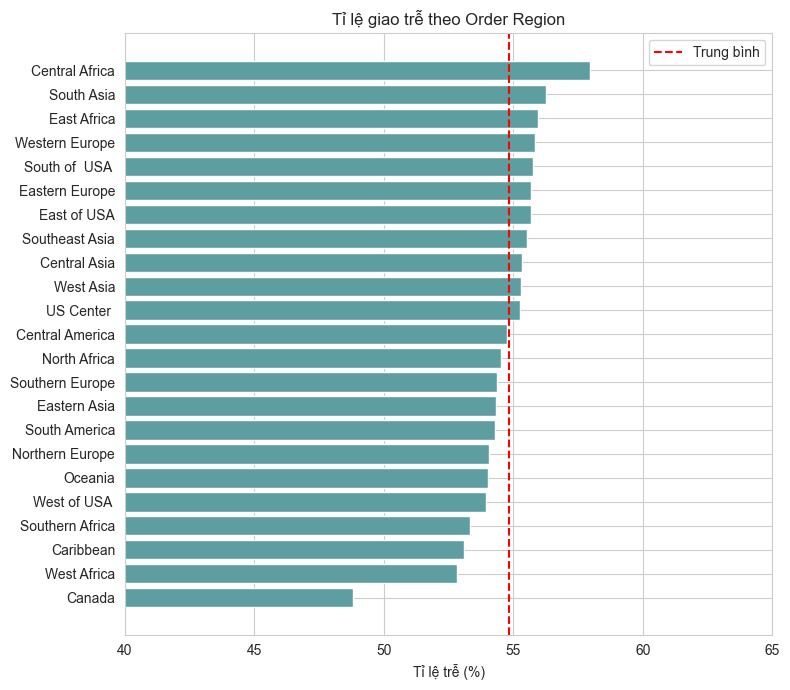

In [35]:
plt.figure(figsize=(8, 7))
plt.barh(region.index, region['mean'], color='cadetblue')
plt.axvline(ti_le_tb, color='red', linestyle='--', label='Trung bình')
plt.xlabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo Order Region')
plt.xlim(40, 65)
plt.legend()
plt.tight_layout()
plt.savefig('figures/fig09_late_by_region.png')
plt.show()

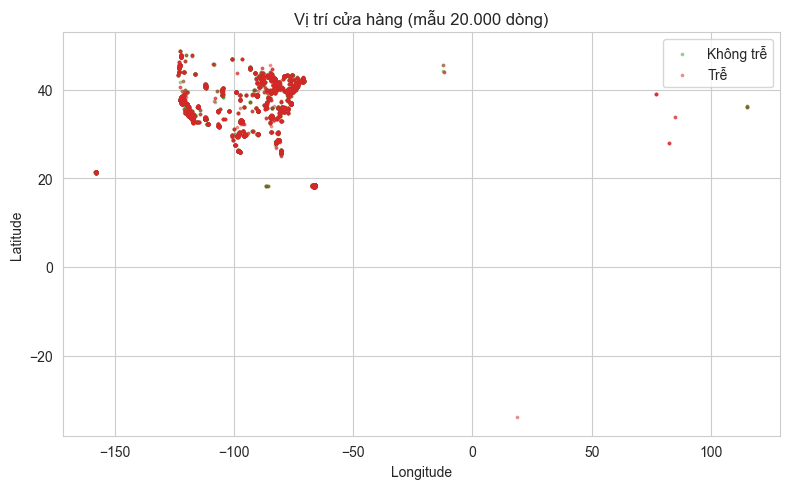

In [36]:
# vị trí cửa hàng (Latitude, Longitude), lấy mẫu 20000 dòng cho nhẹ
sample = df.sample(20000, random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample[sample['Late_delivery_risk'] == 0]['Longitude'], sample[sample['Late_delivery_risk'] == 0]['Latitude'], s=3, alpha=0.4, label='Không trễ', color='tab:green')
plt.scatter(sample[sample['Late_delivery_risk'] == 1]['Longitude'], sample[sample['Late_delivery_risk'] == 1]['Latitude'], s=3, alpha=0.4, label='Trễ', color='tab:red')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Vị trí cửa hàng (mẫu 20.000 dòng)')
plt.legend()
plt.tight_layout()
plt.savefig('figures/fig10_store_location.png')
plt.show()

In [37]:
print(df['Customer Country'].value_counts())

Customer Country
EE. UU.        111146
Puerto Rico     69373
Name: count, dtype: int64


**Nhận xét:**
- Tỉ lệ trễ giữa các Market chỉ từ 54.4% đến 55.2%; giữa các Region từ 48.8% (Canada, ít dòng) đến 58.0% (Central Africa) -> ảnh hưởng yếu.
- Cửa hàng đều nằm ở Mỹ và Puerto Rico, điểm trễ và không trễ trộn lẫn -> vị trí cửa hàng không phân biệt rõ.

## 7. EDA - Sản phẩm và khách hàng

In [38]:
dept = df.groupby('Department Name')['Late_delivery_risk'].agg(['mean', 'count'])
dept['mean'] = dept['mean'] * 100
dept = dept.sort_values('mean')
print(dept)

                         mean  count
Department Name                     
Discs Shop          54.442251   2026
Footwear            54.726334  14525
Apparel             54.747133  48998
Fan Shop            54.774831  66861
Golf                54.780253  33220
Technology          55.017065   1465
Outdoors            55.492463   9686
Fitness             55.546591   2479
Health and Beauty   55.801105    362
Book Shop           56.543210    405
Pet Shop            58.943089    492


In [39]:
cat = df.groupby('Category Name')['Late_delivery_risk'].agg(['mean', 'count'])
cat['mean'] = cat['mean'] * 100
# chỉ lấy 15 category có nhiều dòng nhất
top_cat = cat.sort_values('count', ascending=False).head(15).sort_values('mean')
print(top_cat)

                           mean  count
Category Name                         
Men's Footwear        54.486200  22246
Cardio Equipment      54.496677  12487
Camping & Hiking      54.534198  13729
Women's Apparel       54.556691  21035
Golf Balls            54.576271   1475
Indoor/Outdoor Games  54.746606  19298
Water Sports          54.806950  15540
Fishing               54.926407  17325
Cleats                54.971284  24551
Shop By Sport         55.152950  10984
Girls' Apparel        55.287261   1201
Trade-In              55.646817    974
Electronics           56.083650   3156
Golf Gloves           56.261682   1070
Accessories           56.966292   1780


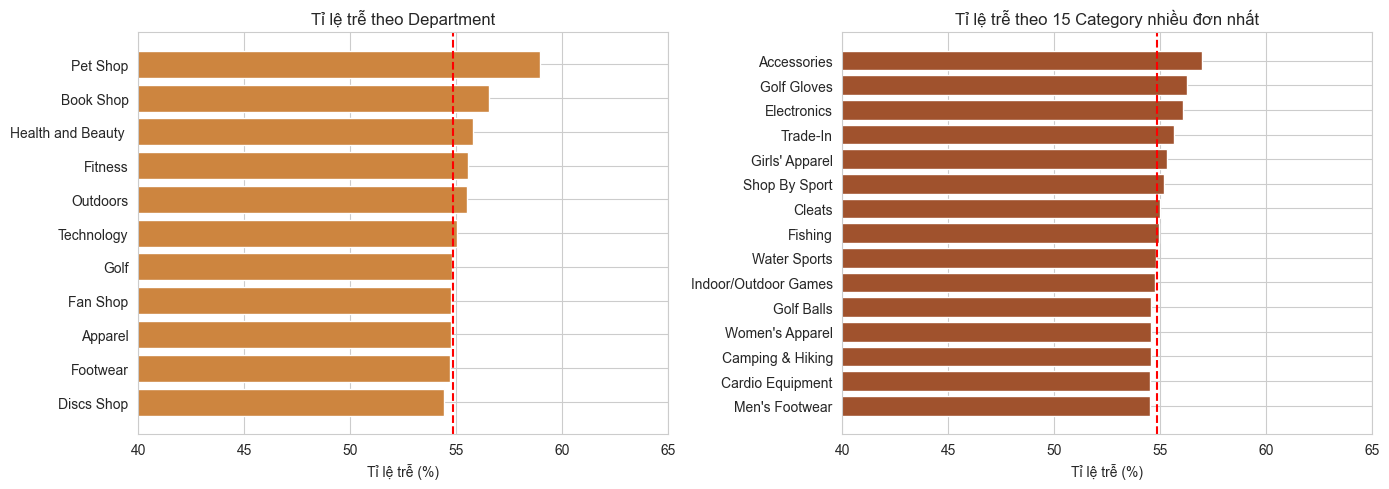

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(dept.index, dept['mean'], color='peru')
ax[0].axvline(ti_le_tb, color='red', linestyle='--')
ax[0].set_xlim(40, 65)
ax[0].set_title('Tỉ lệ trễ theo Department')
ax[0].set_xlabel('Tỉ lệ trễ (%)')
ax[1].barh(top_cat.index, top_cat['mean'], color='sienna')
ax[1].axvline(ti_le_tb, color='red', linestyle='--')
ax[1].set_xlim(40, 65)
ax[1].set_title('Tỉ lệ trễ theo 15 Category nhiều đơn nhất')
ax[1].set_xlabel('Tỉ lệ trễ (%)')
plt.tight_layout()
plt.savefig('figures/fig11_late_by_product.png')
plt.show()

In [41]:
seg = df.groupby('Customer Segment')['Late_delivery_risk'].mean() * 100
typ = df.groupby('Type')['Late_delivery_risk'].agg(['mean', 'count'])
typ['mean'] = typ['mean'] * 100
print(seg)
print(typ)

Customer Segment
Consumer       54.808350
Corporate      54.722663
Home Office    55.070440
Name: Late_delivery_risk, dtype: float64
               mean  count
Type                      
CASH      56.632341  19616
DEBIT     57.217692  69295
PAYMENT   57.529059  41725
TRANSFER  48.543592  49883


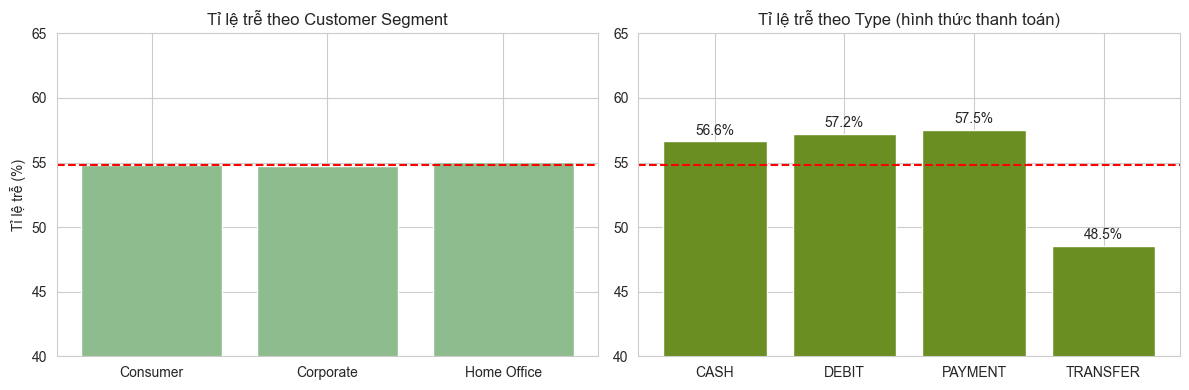

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(seg.index, seg.values, color='darkseagreen')
ax[0].axhline(ti_le_tb, color='red', linestyle='--')
ax[0].set_ylim(40, 65)
ax[0].set_title('Tỉ lệ trễ theo Customer Segment')
ax[0].set_ylabel('Tỉ lệ trễ (%)')
ax[1].bar(typ.index, typ['mean'], color='olivedrab')
ax[1].axhline(ti_le_tb, color='red', linestyle='--')
ax[1].set_ylim(40, 65)
ax[1].set_title('Tỉ lệ trễ theo Type (hình thức thanh toán)')
for i in range(len(typ)):
    ax[1].text(i, typ['mean'].iloc[i] + 0.5, str(round(typ['mean'].iloc[i], 1)) + '%', ha='center')
plt.tight_layout()
plt.savefig('figures/fig12_late_by_customer_type.png')
plt.show()

In [43]:
# Type = PAYMENT, CASH ... liên quan với Order Status không?
print(pd.crosstab(df['Type'], df['Order Status']))

Order Status  CANCELED  CLOSED  COMPLETE  ON_HOLD  PAYMENT_REVIEW  PENDING  \
Type                                                                         
CASH                 0   19616         0        0               0        0   
DEBIT                0       0     59491     9804               0        0   
PAYMENT              0       0         0        0            1893        0   
TRANSFER          3692       0         0        0               0    20227   

Order Status  PENDING_PAYMENT  PROCESSING  SUSPECTED_FRAUD  
Type                                                        
CASH                        0           0                0  
DEBIT                       0           0                0  
PAYMENT                 39832           0                0  
TRANSFER                    0       21902             4062  


**Nhận xét:**
- Department, Category, Customer Segment: tỉ lệ trễ gần như bằng trung bình -> ảnh hưởng yếu.
- `Type = TRANSFER` có tỉ lệ trễ thấp hơn (~47%) vì nhóm này chứa toàn bộ đơn bị hủy/nghi gian lận (luôn là "không trễ"). Đây là tín hiệu gián tiếp từ việc hủy đơn chứ không phải do vận chuyển.

## 8. EDA - Biến số và tương quan

In [44]:
cot_so = ['Sales', 'Order Item Quantity', 'Product Price', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Profit Per Order']
df[cot_so].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,180519.0,203.772096,132.273077,9.99000,119.980003,199.919998,299.950012,1999.989990
Order Item Quantity,180519.0,2.127638,1.453451,1.00000,1.000000,1.000000,3.000000,5.000000
Product Price,180519.0,141.232550,139.732492,9.99000,50.000000,59.990002,199.990005,1999.989990
Order Item Discount Rate,180519.0,0.101668,0.070415,0.00000,0.040000,0.100000,0.160000,0.250000
Order Item Profit Ratio,180519.0,0.120647,0.466796,-2.75000,0.080000,0.270000,0.360000,0.500000
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988


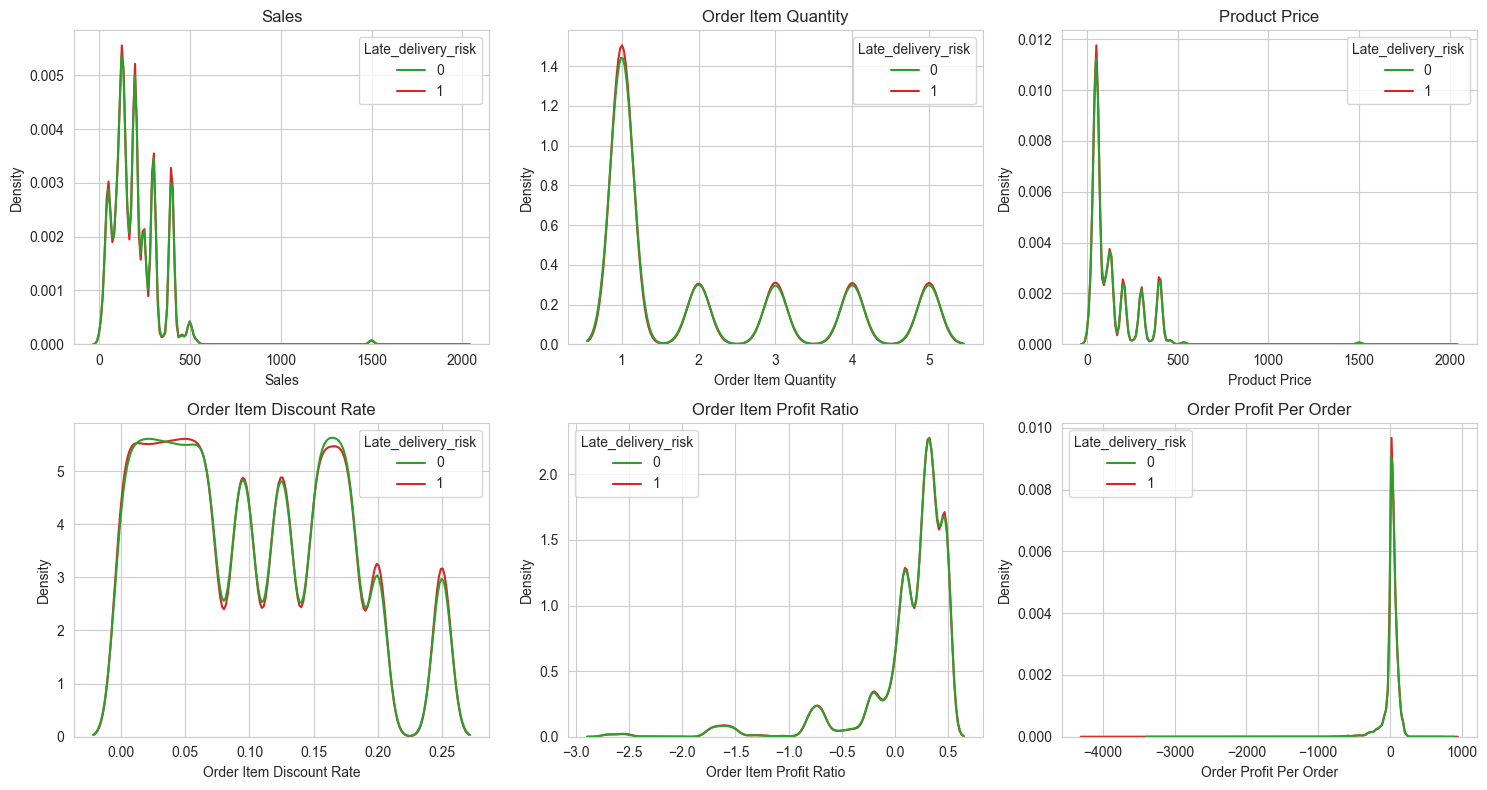

In [45]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i in range(len(cot_so)):
    col = cot_so[i]
    sns.kdeplot(data=df, x=col, hue='Late_delivery_risk', common_norm=False, ax=ax[i], palette=['tab:green', 'tab:red'])
    ax[i].set_title(col)
plt.tight_layout()
plt.savefig('figures/fig13_numeric_kde.png')
plt.show()

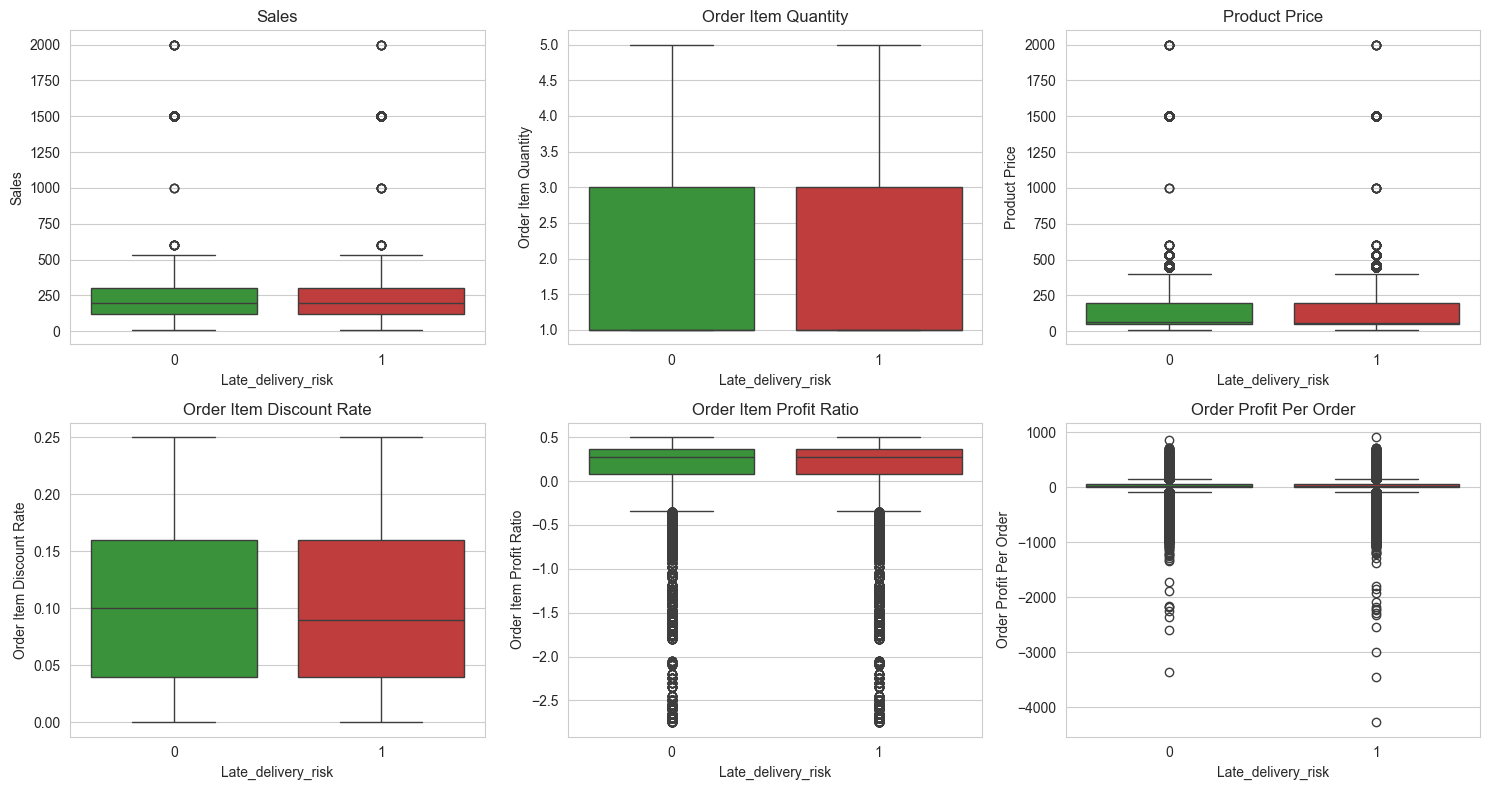

In [46]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i in range(len(cot_so)):
    col = cot_so[i]
    sns.boxplot(data=df, x='Late_delivery_risk', y=col, ax=ax[i], palette=['tab:green', 'tab:red'])
    ax[i].set_title(col)
plt.tight_layout()
plt.savefig('figures/fig14_numeric_boxplot.png')
plt.show()

In [47]:
# so sánh trung bình 2 nhóm
print(df.groupby('Late_delivery_risk')[cot_so].mean().T)

Late_delivery_risk                 0           1
Sales                     204.291528  203.344163
Order Item Quantity         2.127860    2.127454
Product Price             141.567424  140.956665
Order Item Discount Rate    0.101637    0.101694
Order Item Profit Ratio     0.121837    0.119666
Order Profit Per Order     22.403808   21.621707


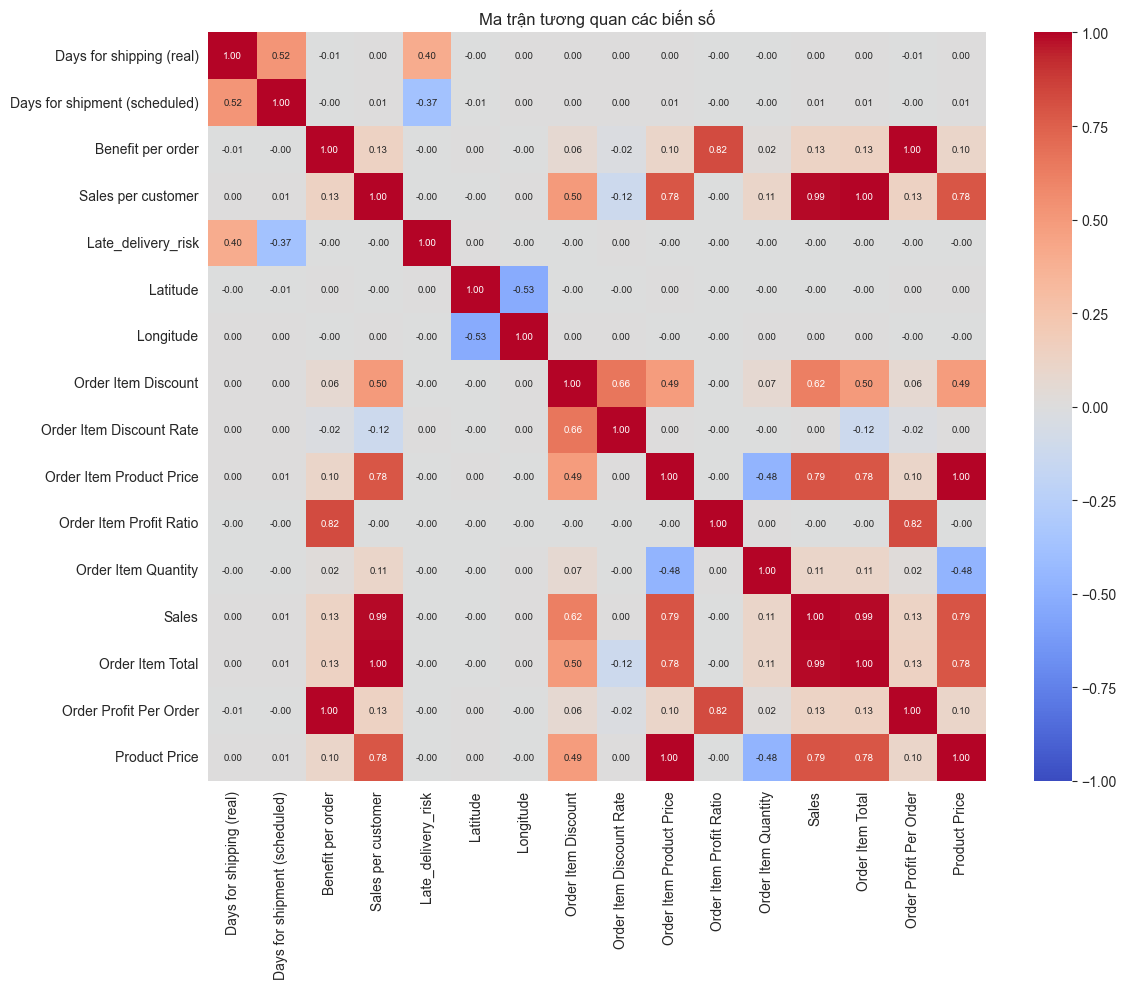

In [48]:
# heatmap tương quan giữa các cột số
cot_so_all = ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer',
              'Late_delivery_risk', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate',
              'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
              'Order Item Total', 'Order Profit Per Order', 'Product Price']
corr = df[cot_so_all].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Ma trận tương quan các biến số')
plt.tight_layout()
plt.savefig('figures/fig15_correlation.png')
plt.show()

In [49]:
# tìm các cặp cột giống hệt nhau
cap_cot = [('Benefit per order', 'Order Profit Per Order'),
           ('Sales per customer', 'Order Item Total'),
           ('Product Price', 'Order Item Product Price'),
           ('Order Customer Id', 'Customer Id'),
           ('Category Id', 'Product Category Id'),
           ('Product Card Id', 'Order Item Cardprod Id')]
for a, b in cap_cot:
    print(a, '==', b, ':', (df[a] == df[b]).all())

Benefit per order == Order Profit Per Order : True
Sales per customer == Order Item Total : True
Product Price == Order Item Product Price : True
Order Customer Id == Customer Id : True
Category Id == Product Category Id : True
Product Card Id == Order Item Cardprod Id : True


In [50]:
# tương quan với target
print(corr['Late_delivery_risk'].sort_values(ascending=False))

Late_delivery_risk               1.000000
Days for shipping (real)         0.401415
Latitude                         0.000679
Order Item Discount Rate         0.000404
Order Item Quantity             -0.000139
Order Item Discount             -0.000750
Longitude                       -0.001915
Order Item Product Price        -0.002175
Product Price                   -0.002175
Order Item Profit Ratio         -0.002316
Sales                           -0.003564
Benefit per order               -0.003727
Order Profit Per Order          -0.003727
Order Item Total                -0.003791
Sales per customer              -0.003791
Days for shipment (scheduled)   -0.369352
Name: Late_delivery_risk, dtype: float64


**Nhận xét:**
- Phân bố của các biến tiền/giá/số lượng giữa nhóm trễ và không trễ gần như trùng nhau.
- Có nhiều cột **giống hệt nhau** (Benefit per order = Order Profit Per Order, Product Price = Order Item Product Price, ...) và nhiều cột tương quan rất cao (Sales, Order Item Total, Sales per customer) -> chỉ giữ 1 cột.
- Tương quan với target: chỉ `Days for shipping (real)` (leakage) và `Days for shipment (scheduled)` (âm) đáng kể.

## 9. Tiền xử lý dữ liệu

In [51]:
# 1. cột bị leakage
cot_leak = ['Delivery Status', 'Days for shipping (real)', 'shipping date (DateOrders)', 'Order Status']

# 2. cột thông tin cá nhân / định danh / không có ích
cot_dinh_danh = ['Customer Email', 'Customer Password', 'Customer Fname', 'Customer Lname', 'Customer Street',
                 'Customer Zipcode', 'Customer Id', 'Order Customer Id', 'Order Id', 'Order Item Id',
                 'Product Image', 'Product Name', 'Product Card Id', 'Order Item Cardprod Id',
                 'Category Id', 'Product Category Id', 'Department Id']

# 3. cột missing nhiều hoặc chỉ có 1 giá trị
cot_missing = ['Product Description', 'Order Zipcode', 'Product Status']

# 4. cột trùng lặp
cot_trung = ['Benefit per order', 'Sales per customer', 'Order Item Total', 'Order Item Product Price', 'Order Item Discount']

# 5. cột có quá nhiều giá trị (high cardinality) - tạm bỏ ở submission 1
cot_nhieu_gia_tri = ['Customer City', 'Customer State', 'Order City', 'Order State', 'Order Country', 'Customer Country']

cot_bo = cot_leak + cot_dinh_danh + cot_missing + cot_trung + cot_nhieu_gia_tri
print('Số cột bỏ:', len(cot_bo))

data = df.drop(columns=cot_bo)
print('Số cột còn lại:', data.shape[1])
print(data.columns.tolist())

Số cột bỏ: 35
Số cột còn lại: 18
['Type', 'Days for shipment (scheduled)', 'Late_delivery_risk', 'Category Name', 'Customer Segment', 'Department Name', 'Latitude', 'Longitude', 'Market', 'order date (DateOrders)', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Profit Per Order', 'Order Region', 'Product Price', 'Shipping Mode']


In [52]:
# lưu bảng danh sách cột bỏ để làm minh chứng
bang_bo = []
for c in cot_leak: bang_bo.append([c, 'Leakage'])
for c in cot_dinh_danh: bang_bo.append([c, 'Định danh / cá nhân'])
for c in cot_missing: bang_bo.append([c, 'Missing nhiều / 1 giá trị'])
for c in cot_trung: bang_bo.append([c, 'Trùng lặp'])
for c in cot_nhieu_gia_tri: bang_bo.append([c, 'Quá nhiều giá trị'])
bang_bo = pd.DataFrame(bang_bo, columns=['cot', 'ly_do'])
bang_bo.to_csv('results/cac_cot_bi_bo.csv', index=False, encoding='utf-8-sig')
bang_bo

,cot,ly_do
0,Delivery Status,Leakage
1,Days for shipping (real),Leakage
2,shipping date (DateOrders),Leakage
3,Order Status,Leakage
4,Customer Email,Định danh / cá nhân
5,Customer Password,Định danh / cá nhân
6,Customer Fname,Định danh / cá nhân
7,Customer Lname,Định danh / cá nhân
8,Customer Street,Định danh / cá nhân
9,Customer Zipcode,Định danh / cá nhân


In [53]:
data.head()

,Type,Days for shipment (scheduled),Late_delivery_risk,Category Name,Customer Segment,Department Name,Latitude,Longitude,Market,order date (DateOrders),Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Order Profit Per Order,Order Region,Product Price,Shipping Mode
0,DEBIT,4,0,Sporting Goods,Consumer,Fitness,18.251453,-66.037056,Pacific Asia,1/31/2018 22:56,0.04,0.29,1,327.75,91.250000,Southeast Asia,327.75,Standard Class
1,TRANSFER,4,1,Sporting Goods,Consumer,Fitness,18.279451,-66.037064,Pacific Asia,1/13/2018 12:27,0.05,-0.80,1,327.75,-249.089996,South Asia,327.75,Standard Class
2,CASH,4,0,Sporting Goods,Consumer,Fitness,37.292233,-121.881279,Pacific Asia,1/13/2018 12:06,0.06,-0.80,1,327.75,-247.779999,South Asia,327.75,Standard Class
3,DEBIT,4,0,Sporting Goods,Home Office,Fitness,34.125946,-118.291016,Pacific Asia,1/13/2018 11:45,0.07,0.08,1,327.75,22.860001,Oceania,327.75,Standard Class
4,PAYMENT,4,0,Sporting Goods,Corporate,Fitness,18.253769,-66.037048,Pacific Asia,1/13/2018 11:24,0.09,0.45,1,327.75,134.210007,Oceania,327.75,Standard Class


In [54]:
print(data.isnull().sum().sum(), 'giá trị missing còn lại')

0 giá trị missing còn lại


In [55]:
# one-hot encoding cho các cột chữ (cột order date để nguyên dạng ngày tháng)
cot_chu = data.select_dtypes(include='object').columns.tolist()
cot_chu.remove('order date (DateOrders)')
print('Các cột chữ:', cot_chu)
for c in cot_chu:
    print(c, ':', data[c].nunique(), 'giá trị')

Các cột chữ: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Market', 'Order Region', 'Shipping Mode']
Type : 4 giá trị
Category Name : 50 giá trị
Customer Segment : 3 giá trị
Department Name : 11 giá trị
Market : 5 giá trị
Order Region : 23 giá trị
Shipping Mode : 4 giá trị


In [56]:
data_encoded = pd.get_dummies(data, columns=cot_chu, drop_first=True)
print('Kích thước sau one-hot:', data_encoded.shape)

Kích thước sau one-hot: (180519, 104)


## 10. Tổng kết Submission 1

- Bài toán: **binary classification**, target `Late_delivery_risk` (54.8% trễ / 45.2% không trễ).
- Đã phát hiện và loại bỏ **4 cột leakage**: chỉ riêng luật `real > scheduled` đã khớp 97.55% với target.
- EDA cho thấy **Shipping Mode / Days for shipment (scheduled)** là yếu tố mạnh nhất (First Class trễ 95.3%, Standard Class 38.1%); các yếu tố địa lý, sản phẩm, khách hàng, giá trị đơn chỉ ảnh hưởng yếu.
- Tiền xử lý: bỏ 35 cột, one-hot encoding cho các cột chữ.

**Hướng làm tiếp:**
- Nghiên cứu EDA theo thời gian (ngày/giờ đặt hàng).
- Thử target encoding cho các cột nhiều giá trị (Order Country, Order City).
- Xây dựng mô hình (đang thử nghiệm, chưa chốt).
- Mở rộng sang multiclass với `Delivery Status`.